# Домашнее задание по теме "Ad-hoc аналитика"
### Выполнила: Кудрявцева Екатерина

### Тема

> 20 июля на Android кликабельность `top_search` резко выше обычной. Что это: ошибка трекинга, и тогда чиним логирование, или реальный эффект, и тогда решаем, менять ли формат показа на Android?


| Поле ТЗ | Значение |
|---|---|
| Цель | Определить, что вызвало скачок кликабельности top-search на Android 20 июля |
| Гипотеза | Скачок связан с повторным логированием кликов или ошибкой их привязки к показам. После исключения некорректных событий CTR вернется к обычному уровню |
| Метрика | CTR - доля показов с хотя бы одним кликом, дополнительно - доля показов с откликом |
| Период | 	1-28 июля 2026: 20 июля - день скачка, 1–19 июля - фон, 21–28 июля - проверка повторяемости |
| Сегменты | по сегментам работодателей внутри Android (Если аномалия в одном сегменте, проверить, не приходится ли избыток кликов на отдельных работодателей, вакансии или пользователей) |
| Критерий | Если после очистки данных CTR 20 июля соответствует обычному разбросу 1-19 июля - ошибка трекинга, если сохранился выше обычного - проверить долю показов с откликом |
| Решение | При ошибке трекинга - чиним логирование, если рост сохраняется и сопровождается ростом доли показов с откликом - предложить A/B тест формата. Если причина не установлена, а рост доли показов с откликом не подтвержден - формат не меняем и тест не запускаем. Продолжаем контроль, и если скачок не повторится, то все оставляем без изменений.  |

Глубина: разбор. Средняя цена ошибки, принимаем решение оставить или убрать, если что можно достаточно быстро откатить.   

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

try:
    import duckdb
except ImportError as e:
    raise ImportError("Нужен пакет duckdb для SQL-блоков: pip install duckdb") from e

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.titlesize"] = 12

# Канонический путь: analytics_school/data рядом с ноутбуком
DATA = Path("data")
if not DATA.exists():
    # запасной вариант, если ядро запущено из корня репозитория
    DATA = Path("hh-science/k.guliev/analytics_school/data")

assert DATA.exists(), f"Не найдена папка с данными: {DATA.resolve()}"

# Регистрируем CSV как таблицы, чтобы обращаться к ним из SQL
con = duckdb.connect()

def register_csv(name: str, filename: str) -> pd.DataFrame:
    path = DATA / filename
    df = pd.read_csv(path)
    # year/month/day должны остаться строками с ведущими нулями ('07'),
    # иначе фильтр вида day BETWEEN '01' AND '28' сравнит строки неправильно
    for col in ("year", "month", "day"):
        if col in df.columns:
            if col == "year":
                df[col] = df[col].astype("Int64").astype(str)
            else:
                df[col] = df[col].astype("Int64").map(lambda x: f"{int(x):02d}" if pd.notna(x) else None)
    con.register(name, df)
    print(f"{name:28s} {len(df):>8,} строк  <- {filename}")
    return df

impressions = register_csv("impressions", "impressions.csv")
clicks = register_csv("clicks", "clicks.csv")
responses = register_csv("responses", "responses.csv")
product_daily = register_csv("product_daily", "product_daily.csv")
employer_spend = register_csv("employer_spend", "employer_spend.csv")
experiment_clients = register_csv("experiment_clients", "experiment_clients.csv")
incident_events = register_csv("incident_events", "incident_events.csv")

def sql(query: str) -> pd.DataFrame:
    # Выполнить SQL-запрос (в стиле Trino) к синтетическим таблицам
    return con.execute(query).df()

print("\nГотово. Для запросов используйте функцию sql('''...''').")


impressions                    80,000 строк  <- impressions.csv
clicks                          3,837 строк  <- clicks.csv
responses                         421 строк  <- responses.csv
product_daily                     252 строк  <- product_daily.csv
employer_spend                  2,400 строк  <- employer_spend.csv
experiment_clients             12,573 строк  <- experiment_clients.csv
incident_events                25,500 строк  <- incident_events.csv

Готово. Для запросов используйте функцию sql('''...''').


In [2]:
from typing import Iterable, Optional, Sequence, Tuple


def wilson_ci(successes: float, n: float, z: float = 1.96) -> Tuple[float, float]:
    # Доверительный интервал Уилсона для доли. Устойчивее нормального приближения
    # на малых выборках и у краёв (доля близка к 0 или 1).
    if n <= 0:
        return (np.nan, np.nan)
    p = successes / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    margin = z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n) / denom
    return (max(0.0, center - margin), min(1.0, center + margin))


def proportion_table(
    df: pd.DataFrame,
    group_cols: Sequence[str],
    success_col: str,
    n_col: str,
    rate_name: str = "rate",
) -> pd.DataFrame:
    # Считает долю по группам и добавляет доверительный интервал Уилсона.
    g = df.groupby(list(group_cols), as_index=False).agg(
        successes=(success_col, "sum"),
        n=(n_col, "sum"),
    )
    g[rate_name] = g["successes"] / g["n"]
    cis = g.apply(lambda r: wilson_ci(r["successes"], r["n"]), axis=1)
    g["ci_low"] = cis.map(lambda x: x[0])
    g["ci_high"] = cis.map(lambda x: x[1])
    return g


def period_flag(dates: pd.Series, cutoff: str, before="before", after="after") -> pd.Series:
    # Размечает даты на период до и после точки cutoff.
    d = pd.to_datetime(dates)
    return np.where(d < pd.Timestamp(cutoff), before, after)


def summarize_dq(df: pd.DataFrame, key_cols: Optional[Iterable[str]] = None) -> pd.DataFrame:
    # Быстрая сводка по качеству данных: размер, дубли, пропуски по колонкам,
    # при указании ключа считаем также дубли по ключу.
    rows = []
    rows.append({"проверка": "строк всего", "значение": len(df)})
    rows.append({"проверка": "полных дублей строк", "значение": int(df.duplicated().sum())})
    for c in df.columns:
        rows.append({"проверка": f"пропуски: {c}", "значение": int(df[c].isna().sum())})
    if key_cols:
        key_cols = list(key_cols)
        rows.append({
            "проверка": f"дубли по ключу: {'+'.join(key_cols)}",
            "значение": int(df.duplicated(key_cols).sum()),
        })
    return pd.DataFrame(rows)


def one_pager(
    decision: str,
    context: str,
    what_done: str,
    result: str,
    limits: str,
    action: str,
) -> str:
    # Собирает итоговую справку с выводом наверху.
    parts = [
        "=" * 60,
        "ИТОГОВАЯ СПРАВКА",
        "=" * 60,
        "",
        "Решение:",
        decision,
        "",
        "Контекст:",
        context,
        "",
        "Что сделали:",
        what_done,
        "",
        "Результат:",
        result,
        "",
        "Ограничения:",
        limits,
        "",
        "Рекомендованное действие:",
        action,
        "=" * 60,
    ]
    return "\n".join(parts)


print("Функции загружены: wilson_ci, proportion_table, period_flag, summarize_dq, one_pager")


Функции загружены: wilson_ci, proportion_table, period_flag, summarize_dq, one_pager


## Проверка качества данных

In [3]:
funnel_sources = {
    'impressions': (impressions, 'impression_id'),
    'clicks': (clicks, 'click_id'),
    'responses': (responses, 'response_id'),
}

dq_summary = pd.concat({
    name: summarize_dq(frame, [key]).set_index('проверка')['значение']
    for name, (frame, key) in funnel_sources.items()
}, axis=1).astype('Int64')
display(dq_summary)

,impressions,clicks,responses
проверка,,,
строк всего,80000,3837,421
полных дублей строк,0,0,0
пропуски: impression_id,0,0,0
пропуски: event_date,0,0,0
пропуски: platform,0,0,0
пропуски: segment,0,0,0
пропуски: product,0,0,0
пропуски: vacancy_id,0,0,0
пропуски: employer_id,0,0,0


Для связности проверяю, что у каждого клика есть показ, а у каждого отклика — клик по тому же показу. У связанных событий должны совпадать платформа, продукт, сегмент, вакансия, работодатель и пользователь; дата клика или отклика не может быть раньше даты предыдущего события

In [4]:
def check_links(events, parent, key, fields):
    pairs = events.merge(
        parent[[key, 'event_date', *fields]],
        on=key, how='left', suffixes=('', '_parent'),
        indicator=True, validate='many_to_one',
    )
    matched = pairs.loc[pairs['_merge'].eq('both')]
    parent_fields = matched[[f'{field}_parent' for field in fields]].set_axis(fields, axis=1)
    dates = pd.to_datetime(matched['event_date'], format='%Y-%m-%d')
    parent_dates = pd.to_datetime(matched['event_date_parent'], format='%Y-%m-%d')
    return {
        'нет связанного события': len(pairs) - len(matched),
        'атрибуты или ID показа не совпадают': int(matched[fields].ne(parent_fields).any(axis=1).sum()),
        'клик или отклик раньше предыдущего события': int(dates.lt(parent_dates).sum()),
    }


context_fields = ['platform', 'product', 'segment', 'vacancy_id', 'employer_id', 'hhuid']
dq_links = pd.DataFrame({
    'клик - показ': check_links(clicks, impressions, 'impression_id', context_fields),
    'отклик - клик': check_links(responses, clicks, 'click_id', [*context_fields, 'impression_id']),
})
display(dq_links)

,клик - показ,отклик - клик
нет связанного события,0,0
атрибуты или ID показа не совпадают,0,0
клик или отклик раньше предыдущего события,0,0


Для анализа оставляю показы top_search на Android за 1–28 июля 2026, а клики и отклики отбираю по связям с этими показами. Для сравнения воронки дату и сегмент беру из показа

In [5]:
impressions_scope = impressions.loc[
    impressions['platform'].eq('ANDROID')
    & impressions['product'].eq('top_search')
    & impressions['event_date'].between('2026-07-01', '2026-07-28')
].copy()
clicks_scope = clicks.loc[clicks['impression_id'].isin(impressions_scope['impression_id'])].copy()
responses_scope = responses.loc[responses['click_id'].isin(clicks_scope['click_id'])].copy()

con.register('impressions_scope', impressions_scope)
con.register('clicks_scope', clicks_scope)
con.register('responses_scope', responses_scope)

dq_coverage = sql('''
    SELECT 'Показы' AS "Событие", COUNT(*) AS "Записей",
           COUNT(DISTINCT event_date) AS "Дней с событием",
           COUNT(*) FILTER (WHERE event_date = '2026-07-20') AS "Записей 20 июля",
           COUNT(DISTINCT impression_id) AS "Уникальных показов"
    FROM impressions_scope
    UNION ALL
    SELECT 'Клики', COUNT(*), COUNT(DISTINCT event_date),
           COUNT(*) FILTER (WHERE event_date = '2026-07-20'), COUNT(DISTINCT impression_id)
    FROM clicks_scope
    UNION ALL
    SELECT 'Отклики', COUNT(*), COUNT(DISTINCT event_date),
           COUNT(*) FILTER (WHERE event_date = '2026-07-20'), COUNT(DISTINCT impression_id)
    FROM responses_scope
''')
display(dq_coverage)

,Событие,Записей,Дней с событием,Записей 20 июля,Уникальных показов
0,Показы,14281,28,383,14281
1,Клики,480,28,36,480
2,Отклики,67,24,4,67


In [6]:
#отдельно для 20 июля
sql("""
    SELECT 'Показы' AS событие, COUNT(*) AS количество
    FROM impressions_scope
    WHERE event_date = '2026-07-20'

    UNION ALL

    SELECT 'Клики', COUNT(*)
    FROM clicks_scope
    WHERE event_date = '2026-07-20'

    UNION ALL

    SELECT 'Отклики', COUNT(*)
    FROM responses_scope
    WHERE event_date = '2026-07-20'
""")

,событие,количество
0,Показы,383
1,Клики,36
2,Отклики,4


Пропусков, дублей и нарушений в связях, атрибутах или порядке дат нет. Очистка не потребовалась

В выборке "Android - top_search" — 14 281 показ, 480 кликов по 480 разным показам и 67 откликов. Показы и клики есть во все 28 дней, отклики зарегистрированы в 24 дня. На 20 июля приходится 383 показа, 36 кликов и 4 отклика

Гипотеза о дублях и неверной привязке не подтвердилась: дублей нет, связи между событиями корректны. Однако по имеющимся данным нельзя проверить, все ли реальные события попали в лог и соответствуют ли записанные клики действиям пользователей.

Основная выборка — Android и top_search. Сравниваю 20 июля с фоном 1–19 июля и проверяю повторяемость на 21–28 июля. Дополнительно смотрю ближайшие дни, другие понедельники и соседние сочетания продукта и платформы: они помогают сузить поиск причины

In [7]:
incident_date = pd.Timestamp('2026-07-20')
recent_start = pd.Timestamp('2026-07-15')
before, incident, after = '1–19 июля', '20 июля', '21–28 июля'
period_order = [before, incident, after]

events = sql("""
    WITH clicked AS (SELECT DISTINCT impression_id FROM clicks),
         responded AS (SELECT DISTINCT impression_id FROM responses)
    SELECT shows.impression_id, CAST(shows.event_date AS DATE) AS event_date,
           shows.platform, shows.product, shows.segment, shows.employer_id,
           shows.vacancy_id, shows.hhuid,
           clicked.impression_id IS NOT NULL AS has_click,
           responded.impression_id IS NOT NULL AS has_response
    FROM impressions AS shows
    LEFT JOIN clicked USING (impression_id)
    LEFT JOIN responded USING (impression_id)
    WHERE shows.event_date BETWEEN '2026-07-01' AND '2026-07-28'
""")

funnel = events.loc[events['impression_id'].isin(impressions_scope['impression_id'])].copy()
funnel['period'] = period_flag(funnel['event_date'], incident_date, before, after)
funnel.loc[funnel['event_date'].eq(incident_date), 'period'] = incident


def funnel_counts(rows, group_cols):
    return rows.groupby(group_cols).agg(
        impressions=('impression_id', 'size'),
        clicks=('has_click', 'sum'),
        responses=('has_response', 'sum'),
    )


def pct(value):
    return f'{value:.2%}'.replace('.', ',')


def rate_with_interval(successes, total):
    low, high = wilson_ci(successes, total)
    return f'{pct(successes / total)} [{pct(low)}; {pct(high)}]'


daily = funnel_counts(funnel, ['event_date']).sort_index()
daily['ctr'] = daily['clicks'] / daily['impressions']
period_counts = funnel_counts(funnel, ['period']).loc[period_order]
rate_specs = {
    'CTR': ('clicks', 'impressions'),
    'Показ - отклик': ('responses', 'impressions'),
    'Клик - отклик': ('responses', 'clicks'),
}

funnel_table = period_counts.rename(columns={
    'impressions': 'Показы', 'clicks': 'Показы с кликом', 'responses': 'Показы с откликом',
})
for label, (numerator, denominator) in rate_specs.items():
    funnel_table[label] = [
        rate_with_interval(successes, total)
        for successes, total in zip(period_counts[numerator], period_counts[denominator])
    ]
display(funnel_table.rename_axis('Период'))

,Показы,Показы с кликом,Показы с откликом,CTR,Показ - отклик,Клик - отклик
Период,,,,,,
1–19 июля,10813,352,47,"3,26% [2,94%; 3,61%]","0,43% [0,33%; 0,58%]","13,35% [10,19%; 17,30%]"
20 июля,383,36,4,"9,40% [6,87%; 12,74%]","1,04% [0,41%; 2,65%]","11,11% [4,41%; 25,32%]"
21–28 июля,3085,92,16,"2,98% [2,44%; 3,64%]","0,52% [0,32%; 0,84%]","17,39% [11,00%; 26,40%]"


Единица расчета в таблице - уникальный показ: CTR - доля показов с кликом, "показ - отклик" - доля показов с откликом, "клик - отклик" - доля кликнутых показов с откликом. В квадратных скобках — 95%-е интервалы Уилсона

In [8]:
volume_windows = {
    '1–14 июля': daily.index < recent_start,
    '15–19 июля': (daily.index >= recent_start) & (daily.index < incident_date),
    incident: daily.index == incident_date,
    after: daily.index > incident_date,
}
volume_table = []
for label, mask in volume_windows.items():
    days = daily.loc[mask]
    volume_table.append({
        'Период': label,
        'Показов в день (среднее)': days['impressions'].mean(),
        'Показов с кликом в день (среднее)': days['clicks'].mean(),
        'CTR за период': pct(days['clicks'].sum() / days['impressions'].sum()),
        'Максимальный дневной CTR': pct(days['ctr'].max()),
    })
display(pd.DataFrame(volume_table).set_index('Период').round(1))

recent = daily.loc[volume_windows['15–19 июля']]
expected_clicks = daily.at[incident_date, 'impressions'] * recent['clicks'].sum() / recent['impressions'].sum()
print(f'Ожидалось около {expected_clicks:.0f} показов с кликом при CTR 15–19 июля')

mondays = daily.loc[daily.index.dayofweek == incident_date.dayofweek, ['impressions', 'clicks', 'ctr']].copy()
mondays['ctr'] = mondays['ctr'].map(pct)
display(mondays.rename(columns={'impressions': 'Показы', 'clicks': 'Показы с кликом', 'ctr': 'CTR'}))

,Показов в день (среднее),Показов с кликом в день (среднее),CTR за период,Максимальный дневной CTR
Период,,,,
1–14 июля,636.3,21.2,"3,33%","4,35%"
15–19 июля,381.0,11.0,"2,89%","4,01%"
20 июля,383.0,36.0,"9,40%","9,40%"
21–28 июля,385.6,11.5,"2,98%","4,47%"


Ожидалось около 11 показов с кликом при CTR 15–19 июля


,Показы,Показы с кликом,CTR
event_date,,,
2026-07-06,670,15,"2,24%"
2026-07-13,636,25,"3,93%"
2026-07-20,383,36,"9,40%"
2026-07-27,380,17,"4,47%"


С 15 июля показов стало меньше, поэтому отдельно сравниваю 20 июля с 15-19 июля. В ближайшие дни было в среднем 381 показ и 11 показов с кликом; 20 июля - 383 и 36. При прежнем CTR на 383 показа ожидалось около 11 кликов то есть в логах примерно на 25 больше этого ориентира.     
Также, другие понедельники не дают такого скачка: CTR 2,24%, 3,93% и 4,47%. Поэтому недельный тренд также отследить нельзя. С 21 по 28 июля дневной CTR не превысил 4,47%

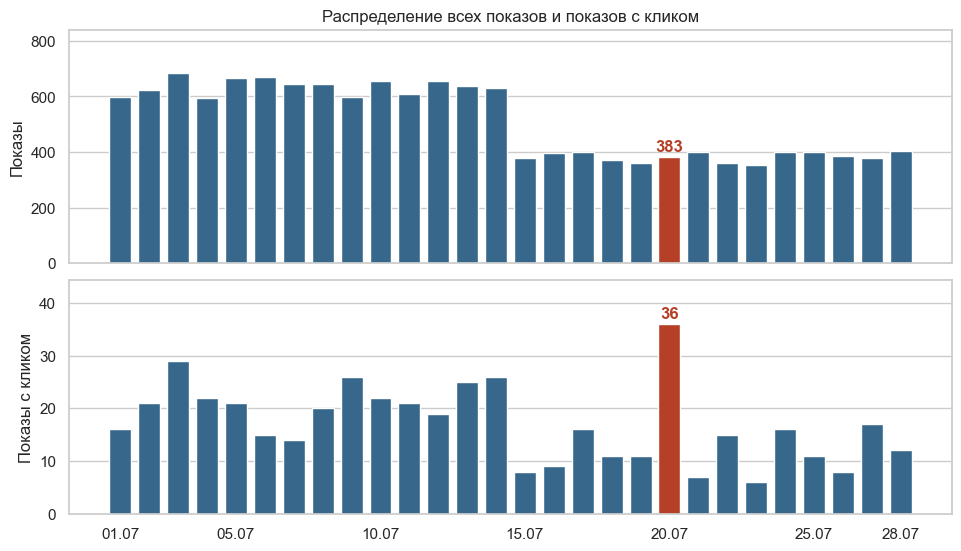

In [9]:
from matplotlib.dates import DateFormatter, DayLocator
from matplotlib.ticker import PercentFormatter

normal_color = "#37688B"
incident_color = '#B64027'

volume_figure, volume_axes = plt.subplots(
    2, 1, sharex=True, figsize=(9.5, 5.4), layout='constrained',
)
for axis, column, label in zip(volume_axes, ['impressions', 'clicks'], ['Показы', 'Показы с кликом']):
    colors = np.where(daily.index == incident_date, incident_color, normal_color)
    axis.bar(daily.index, daily[column], width=0.76, color=colors)
    axis.annotate(str(daily.at[incident_date, column]), (incident_date, daily.at[incident_date, column]),
                  xytext=(0, 4), textcoords='offset points', ha='center',
                  color=incident_color, fontweight='bold')
    axis.set(ylabel=label, ylim=(0, daily[column].max() * 1.23))
    axis.grid(axis='x', visible=False)
    axis.set_axisbelow(True)

volume_axes[0].set_title('Распределение всех показов и показов с кликом')
volume_axes[1].xaxis.set_major_locator(DayLocator(bymonthday=[1, 5, 10, 15, 20, 25, 28]))
volume_axes[1].xaxis.set_major_formatter(DateFormatter('%d.%m'))
plt.show()

Количество показов 20 июля не выделяется на фоне ближайших дней, сильно выделяются именно показы с кликами. Это объясняет, за счёт чего вырос CTR, но не почему стало больше зарегистрированных кликов.

### Анализ по сегментам

In [10]:
segments_before = funnel_counts(funnel.loc[funnel['period'].eq(before)], ['segment'])
segments_incident = funnel_counts(funnel.loc[funnel['period'].eq(incident)], ['segment'])
segment_baseline_ctr = segments_before['clicks'] / segments_before['impressions']

display(pd.DataFrame({
    'Показов 20 июля': segments_incident['impressions'],
    'С кликом 20 июля': segments_incident['clicks'],
    'CTR 1–19 июля': segment_baseline_ctr.map(pct),
    'CTR 20 июля': (segments_incident['clicks'] / segments_incident['impressions']).map(pct)
}).rename_axis('Сегмент работодателей'))

clicked_on_incident = funnel.loc[funnel['period'].eq(incident) & funnel['has_click']]
display(clicked_on_incident[['employer_id', 'vacancy_id', 'hhuid']].nunique().rename({
    'employer_id': 'Работодатели', 'vacancy_id': 'Вакансии', 'hhuid': 'Пользователи',
}).to_frame('Разных ID среди 36 кликнутых показов'))

,Показов 20 июля,С кликом 20 июля,CTR 1–19 июля,CTR 20 июля
Сегмент работодателей,,,,
Large,111,12,"3,15%","10,81%"
Premium,62,4,"3,60%","6,45%"
SMB,210,20,"3,22%","9,52%"


,Разных ID среди 36 кликнутых показов
Работодатели,36
Вакансии,36
Пользователи,36


Точечный CTR вырос во всех сегментах, а самый большой вклад в число дополнительных кликов дали SMB и Large. У 36 кликнутых показов разные работодатели, вакансии и пользователи; всплеск не сосредоточен на одном ID

Интересно, что в top_boost на Android в тот же день CTR вырос с 5,09% до 11,51%. В top_search на мобильном вебе рост тоже виден, но он меньше: +2,96 п. п. против +6,51 п. п. на Android. Значит, искать причину только в формате top_search на Android слишком узко. Это основание проверить общий для продуктов путь регистрации кликов и затронутые поверхности, а не доказательство общего сбоя

Для всех сочетаний беру одинаковое окно 15–19 июля: в более ранних строках top_boost ещё нет

In [11]:
comparison_cols = ['platform', 'product']
recent_events = events.loc[events['event_date'].between(recent_start, incident_date - pd.Timedelta(days=1))]
incident_events_all = events.loc[events['event_date'].eq(incident_date)]
nearby_other_days = events.loc[events['event_date'].ge(recent_start) & events['event_date'].ne(incident_date)]
nearby_daily = funnel_counts(nearby_other_days, comparison_cols + ['event_date'])

recent_ctr = recent_events.groupby(comparison_cols)['has_click'].mean()
incident_ctr = incident_events_all.groupby(comparison_cols)['has_click'].mean()
other_days_max = (nearby_daily['clicks'] / nearby_daily['impressions']).groupby(level=comparison_cols).max()

surface_comparison = pd.DataFrame({
    'CTR 15-19 июля': recent_ctr.map(pct),
    'CTR 20 июля': incident_ctr.map(pct),
    'Макс. дневной CTR 15-28 июля без 20-го': other_days_max.map(pct),
    'Разница с 15–19 июля, п. п.': (100 * (incident_ctr - recent_ctr)).round(2),
})
display(surface_comparison.sort_values('Разница с 15–19 июля, п. п.', ascending=False))

CTR 15-19 июля CTR 20 июля  \
platform    product                                 
ANDROID     top_search          2,89%       9,40%   
            top_boost           5,09%      11,51%   
MOBILE_WEB  top_search          4,92%       7,88%   
DESKTOP_WEB top_search          5,66%       6,58%   
            top_boost           7,39%       7,93%   
IOS         top_search          2,90%       3,07%   
            top_boost           4,61%       4,30%   
MOBILE_WEB  top_boost           6,03%       5,69%   

                       Макс. дневной CTR 15-28 июля без 20-го  \
platform    product                                             
ANDROID     top_search                                  4,47%   
            top_boost                                   6,93%   
MOBILE_WEB  top_search                                  7,25%   
DESKTOP_WEB top_search                                  6,88%   
            top_boost                                   8,07%   
IOS         top_search                                  5,57%   
            top_boost                                   7,81%   
MOBILE_WEB  top_boost                                   9,73%   

                        Разница с 15–19 июля, п. п.  
platform    product                                  
ANDROID     top_search                         6.51  
            top_boost                          6.42  
MOBILE_WEB  top_search                         2.96  
DESKTOP_WEB top_search                         0.92  
            top_boost                          0.53  
IOS         top_search                         0.18  
            top_boost                         -0.30  
MOBILE_WEB  top_boost                         -0.34

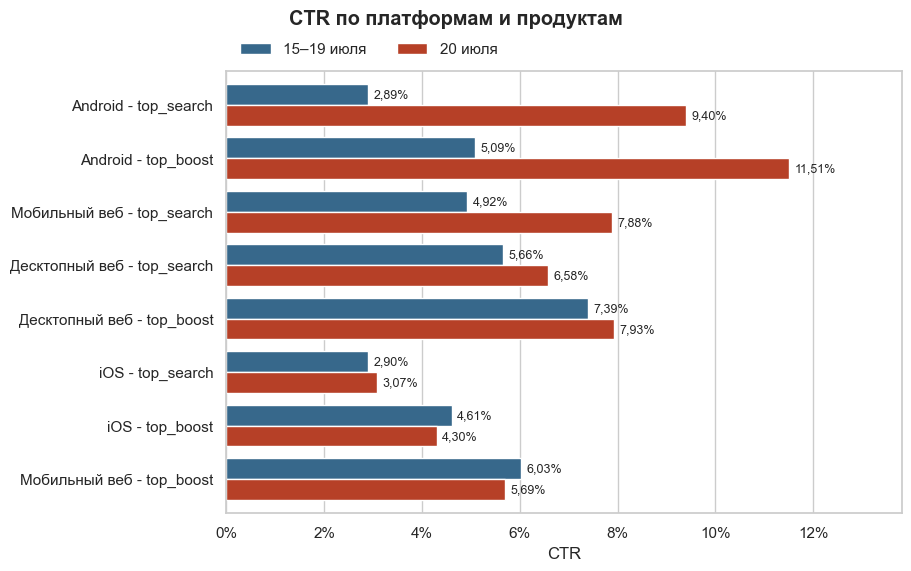

In [12]:
ctr_chart = pd.DataFrame({'15–19 июля': recent_ctr, '20 июля': incident_ctr})
ctr_chart = ctr_chart.loc[(incident_ctr - recent_ctr).sort_values(ascending=False).index]
platform_names = {
    'ANDROID': 'Android', 'IOS': 'iOS',
    'MOBILE_WEB': 'Мобильный веб', 'DESKTOP_WEB': 'Десктопный веб',
}
ctr_chart.index = [f'{platform_names[platform]} - {product}' for platform, product in ctr_chart.index]

surface_figure, surface_axis = plt.subplots(figsize=(9, 5.6), layout='constrained')
ctr_chart.plot.barh(ax=surface_axis, color=[normal_color, incident_color], width=0.78)
for bars in surface_axis.containers:
    surface_axis.bar_label(bars, labels=[pct(bar.get_width()) for bar in bars], padding=4, fontsize=9)

surface_axis.invert_yaxis()
surface_axis.set(xlabel='CTR', xlim=(0, ctr_chart.max().max() * 1.2))
surface_axis.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
surface_axis.grid(axis='y', visible=False)
surface_axis.legend(loc='lower left', bbox_to_anchor=(0, 1), ncol=2, frameon=False)
surface_figure.suptitle('CTR по платформам и продуктам', fontweight='bold')
plt.show()

### Проверка выросло ли значимо число откликов
Доля показов с откликом 20 июля - 1,04% (4 из 383) против 0,43% (47 из 10 813) за 1-19 июля. Откликов мало, поэтому сравниваю доли двусторонним тестом Фишера. Нулевая гипотеза - доли одинаковые; порог значимости - 0,05

In [13]:
from scipy.stats import fisher_exact

response_rates = period_counts['responses'] / period_counts['impressions']
response_intervals = pd.DataFrame(
    [wilson_ci(successes, total) for successes, total in zip(period_counts['responses'], period_counts['impressions'])],
    index=period_order, columns=['low', 'high'],
)

comparison = period_counts.loc[[incident, before]]
with_response = comparison['responses']
without_response = comparison['impressions'] - with_response
fisher_table = np.column_stack([with_response, without_response])
p_value = fisher_exact(fisher_table, alternative='two-sided').pvalue

response_delta = response_rates[incident] - response_rates[before]
delta_text = f'{100 * response_delta:+.2f}'.replace('.', ',')
p_text = f'{p_value:.3f}'.replace('.', ',')
print(f'Разница: {delta_text} п. п.; тест Фишера: p = {p_text}')
if p_value >= 0.05:
    print('Рост доли показов с откликом не подтвержден')

Разница: +0,61 п. п.; тест Фишера: p = 0,096
Рост доли показов с откликом не подтвержден


### Итоговая справка

In [15]:
print(one_pager(
    decision='Формат не менять, A/B-тест пока не запускать. Причина не установлена',
    context='top_search на Android: скачок CTR 20 июля 2026 года. Фон - 1-19 июля, проверка повторяемости - 21-28 июля',
    what_done=('Данные проверены, нет пропусков, дублей и нарушений связей или порядка дат: очистка не потребовалась. Сравнила воронку, ближайшие дни, сегменты, платформы и продукты'),
    result=f'20 июля CTR вырос с фоновых 3,26% до 9,40% за счет большего числа зарегистрированных кликов при обычном числе показов, рост доли показов с откликом не подтвержднен',
    limits='По имеющимся данным нельзя проверить, все ли показы записаны и соответствуют ли зарегистрированные клики реальным нажатиям',
    action=('Две недели ежедневно отслеживать CTR и долю показов с откликом для top_search и top_boost на Android, записывая время событий и версию приложения. '
        'Если скачок повторится, рассмотреть возможность запуска A/B теста.'),
))

ИТОГОВАЯ СПРАВКА

Решение:
Формат не менять, A/B-тест пока не запускать. Причина не установлена

Контекст:
top_search на Android: скачок CTR 20 июля 2026 года. Фон - 1-19 июля, проверка повторяемости - 21-28 июля

Что сделали:
Данные проверены, нет пропусков, дублей и нарушений связей или порядка дат: очистка не потребовалась. Сравнила воронку, ближайшие дни, сегменты, платформы и продукты

Результат:
20 июля CTR вырос с фоновых 3,26% до 9,40% за счет большего числа зарегистрированных кликов при обычном числе показов, рост доли показов с откликом не подтвержднен

Ограничения:
По имеющимся данным нельзя проверить, все ли показы записаны и соответствуют ли зарегистрированные клики реальным нажатиям

Рекомендованное действие:
Две недели ежедневно отслеживать CTR и долю показов с откликом для top_search и top_boost на Android, записывая время событий и версию приложения. Если скачок повторится, рассмотреть возможность запуска A/B теста.
